<a href="https://colab.research.google.com/github/ritaveab/Deep-Learning_hse/blob/main/rnn_hw_Baeva.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Классификация текстов с помощью RNN (PyTorch)

- загрузка и визуализация данных;
- токенизация и словарь;
- RNN-классификатор;
- обучение, кривые, матрица ошибок;
- задания с плейсхолдерами для изменения гиперпараметров.

## 1. Окружение

In [3]:
!pip install -q datasets scikit-learn seaborn tqdm matplotlib

In [4]:
import re
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import (
    pad_sequence,
    pack_padded_sequence
)

from datasets import load_dataset
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

In [5]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    'cuda' if torch.cuda.is_available() else 'cpu'
)

print(f"Using device: {device}")

Using device: cuda


## 2. Загрузка данных

In [6]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nПример:", dataset['train'][0])

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Пример: {'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


In [7]:
train_data = list(zip(
    dataset['train']['label'],
    dataset['train']['text']
))

test_data = list(zip(
    dataset['test']['label'],
    dataset['test']['text']
))

print(f"Обучающих примеров: {len(train_data)}")
print(f"Тестовых примеров: {len(test_data)}")

print(
    f"\nРаспределение меток: "
    f"{Counter(label for label, _ in train_data)}"
)

Обучающих примеров: 120000
Тестовых примеров: 7600

Распределение меток: Counter({2: 30000, 3: 30000, 1: 30000, 0: 30000})


## 3. Визуализация данных

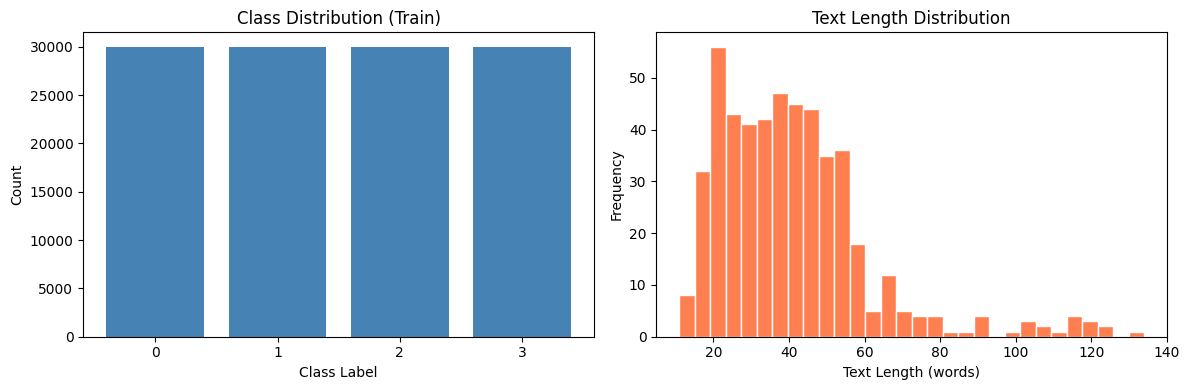

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

labels = [label for label, _ in train_data]
label_counts = Counter(labels)

axes[0].bar(
    label_counts.keys(),
    label_counts.values(),
    color='steelblue'
)

axes[0].set_xlabel('Class Label')
axes[0].set_ylabel('Count')
axes[0].set_title('Class Distribution (Train)')
axes[0].set_xticks([0, 1, 2, 3])

lengths = [
    len(text.split())
    for _, text in train_data[:500]
]

axes[1].hist(
    lengths,
    bins=30,
    color='coral',
    edgecolor='white'
)

axes[1].set_xlabel('Text Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Text Length Distribution')

plt.tight_layout()
plt.show()

In [9]:
print("\n=== Примеры ===")

for i in range(3):
    label, text = train_data[i]
    print(f"[Label {label}] {text[:150]}...")


=== Примеры ===
[Label 2] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again....
[Label 2] Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and ...
[Label 2] Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expecte...


## 4. Токенизация и словарь

In [10]:
def tokenizer(text):
    """
    Простой токенизатор без torchtext.
    Приводит текст к нижнему регистру и отделяет пунктуацию.
    """
    return re.findall(
        r"\w+|[^\w\s]",
        text.lower()
    )


def yield_tokens(data):
    for _, text in data:
        yield tokenizer(text)

In [11]:
def build_vocab_from_iterator(iterator, min_freq=1):
    counter = Counter()

    for tokens in iterator:
        counter.update(tokens)

    # Индексы специальных токенов:
    # <pad> = 0
    # <unk> = 1
    vocab = {
        '<pad>': 0,
        '<unk>': 1,
    }

    frequent_tokens = [
        token
        for token, frequency in counter.items()
        if frequency >= min_freq
        and token not in ('<pad>', '<unk>')
    ]

    # Сначала частые слова, затем алфавитный порядок
    frequent_tokens.sort(
        key=lambda token: (-counter[token], token)
    )

    vocab.update({
        token: index
        for index, token in enumerate(
            frequent_tokens,
            start=2
        )
    })

    return vocab

In [12]:
# ============================================
# Задание 1: параметры построения словаря
# Попробуйте min_freq = 2 или 10. Как меняются размер словаря и качество модели?
# Почему редкие слова могут как помогать, так и мешать?
# ============================================
MIN_FREQ = 5  # <-- меняйте здесь

# Сначала строим словарь только из реальных токенов
vocab = build_vocab_from_iterator(
    yield_tokens(train_data),
    min_freq=MIN_FREQ
)

# Добавляем специальные токены вручную
# Порядок важен: <pad> должен быть первым (индекс 0), <unk> — вторым (индекс 1)

# Устанавливаем токен по умолчанию для неизвестных слов
PAD_IDX = vocab['<pad>']
UNK_IDX = vocab['<unk>']

print(f"Размер словаря: {len(vocab)}")
print(f"PAD_IDX = {PAD_IDX}, UNK_IDX = {UNK_IDX}")

Размер словаря: 27831
PAD_IDX = 0, UNK_IDX = 1


## 5. Предобработка и Dataset

In [13]:
# ============================================
# Задание 2: длина последовательности (обрезка)
# Попробуйте MAX_LEN = 128, 256, 512. Как меняются скорость обучения и точность?
# Почему у RNN может не быть выигрыша от очень длинных последовательностей?
# ============================================
MAX_LEN = 256  # <-- меняйте здесь

In [14]:
def text_pipeline(text):
    tokens = tokenizer(text)

    ids = [
        vocab.get(token, UNK_IDX)
        for token in tokens
    ]

    if len(ids) > MAX_LEN:
        ids = ids[:MAX_LEN]

    # На случай пустого текста
    if len(ids) == 0:
        ids = [UNK_IDX]

    return ids


def label_pipeline(label):
    return label

In [15]:
class AGNewsDataset(torch.utils.data.Dataset):
    def __init__(
        self,
        data,
        text_pipeline,
        label_pipeline
    ):
        self.data = data
        self.text_pipeline = text_pipeline
        self.label_pipeline = label_pipeline

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        label, text = self.data[idx]

        ids = self.text_pipeline(text)

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(
                self.label_pipeline(label),
                dtype=torch.long
            )
        )

In [16]:
def collate_batch(batch):
    text_list, label_list = zip(*batch)

    lengths = torch.tensor(
        [len(text) for text in text_list],
        dtype=torch.long
    )

    padded = pad_sequence(
        text_list,
        batch_first=True,
        padding_value=PAD_IDX
    )

    labels = torch.stack(label_list)

    return padded, lengths, labels

In [17]:
train_dataset = AGNewsDataset(
    train_data,
    text_pipeline,
    label_pipeline
)

test_dataset = AGNewsDataset(
    test_data,
    text_pipeline,
    label_pipeline
)

## 6. DataLoader

In [18]:
# ============================================
# Задание 3: размер батча
# Попробуйте BATCH_SIZE = 32, 64, 128. Как это влияет на стабильность обучения и скорость?
# Документация: https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# ============================================
BATCH_SIZE = 64  # <-- меняйте здесь

In [19]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_batch,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    f"Количество батчей в обучении: "
    f"{len(train_loader)}"
)

Количество батчей в обучении: 1875


## 7. RNN-модель

In [20]:
class RNNClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_dim,
        hidden_dim,
        num_classes,
        num_layers=1,
        dropout=0.2,
        bidirectional=False
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=PAD_IDX
        )

        self.rnn = nn.RNN(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = (
            hidden_dim * 2
            if bidirectional
            else hidden_dim
        )

        self.fc = nn.Linear(
            rnn_output_dim,
            num_classes
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(
            self.embedding(x)
        )

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if self.rnn.bidirectional:
            last_hidden = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )
        else:
            last_hidden = hidden[-1]

        output = self.fc(
            self.dropout(last_hidden)
        )

        return output

In [21]:
# ============================================
# Задание 4: гиперпараметры модели
# Попробуйте разные комбинации и посмотрите на точность на валидации:
#   EMBED_DIM: 64, 128, 256
#   HIDDEN_DIM: 64, 128, 256
#   NUM_LAYERS: 1, 2
#   BIDIRECTIONAL: True / False
# Как размер скрытого состояния связан с числом параметров и качеством?
# ============================================
EMBED_DIM = 128       # <-- меняйте здесь
HIDDEN_DIM = 128      # <-- меняйте здесь
NUM_LAYERS = 1        # <-- меняйте здесь
BIDIRECTIONAL = False # <-- меняйте здесь (True/False)
DROPOUT = 0.2

In [22]:
model = RNNClassifier(
    vocab_size=len(vocab),
    embed_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=4,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    bidirectional=BIDIRECTIONAL
).to(device)

print(model)

print(
    f"Количество обучаемых параметров: "
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

RNNClassifier(
  (embedding): Embedding(27831, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=4, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)
Количество обучаемых параметров: 3,595,908


## 8. Обучение и проверка

In [23]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    for texts, lengths, labels in tqdm(
        loader,
        desc="Training"
    ):
        texts = texts.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(texts, lengths)
        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        predictions = logits.argmax(dim=1)

        total_loss += (
            loss.item() * labels.size(0)
        )

        total_correct += (
            (predictions == labels)
            .sum()
            .item()
        )

        total_samples += labels.size(0)

    return (
        total_loss / total_samples,
        total_correct / total_samples
    )

In [24]:
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    total_correct = 0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for texts, lengths, labels in tqdm(
            loader,
            desc="Evaluating"
        ):
            texts = texts.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            logits = model(texts, lengths)
            loss = criterion(logits, labels)

            predictions = logits.argmax(dim=1)

            total_loss += (
                loss.item() * labels.size(0)
            )

            total_correct += (
                (predictions == labels)
                .sum()
                .item()
            )

            total_samples += labels.size(0)

            all_preds.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return (
        total_loss / total_samples,
        total_correct / total_samples,
        all_preds,
        all_labels
    )

In [25]:
# ============================================
# Задание 5: параметры оптимизатора
# Попробуйте LEARNING_RATE = 1e-3, 5e-4, 1e-4.
# Как скорость обучения влияет на сходимость и стабильность?
# Документация: https://pytorch.org/docs/stable/optim.html#torch.optim.Adam
# ============================================
LEARNING_RATE = 1e-3  # <-- меняйте здесь
NUM_EPOCHS = 5        # <-- меняйте здесь

In [26]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc, _, _ = evaluate(
        model,
        test_loader,
        criterion
    )

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(
        f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Evaluating: 100%|██████████| 119/119 [00:01<00:00, 118.35it/s]


Epoch 1/5 | Train Loss: 0.8881 | Train Acc: 0.6220 | Val Loss: 0.6758 | Val Acc: 0.7532


Evaluating: 100%|██████████| 119/119 [00:00<00:00, 123.02it/s]


Epoch 2/5 | Train Loss: 0.5923 | Train Acc: 0.7969 | Val Loss: 0.5181 | Val Acc: 0.8304


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 115.60it/s]


Epoch 3/5 | Train Loss: 0.5061 | Train Acc: 0.8357 | Val Loss: 0.4894 | Val Acc: 0.8441


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 115.92it/s]


Epoch 4/5 | Train Loss: 0.4484 | Train Acc: 0.8595 | Val Loss: 0.4361 | Val Acc: 0.8667


Evaluating: 100%|██████████| 119/119 [00:01<00:00, 116.06it/s]

Epoch 5/5 | Train Loss: 0.4016 | Train Acc: 0.8743 | Val Loss: 0.4282 | Val Acc: 0.8697


## 9. Кривые обучения

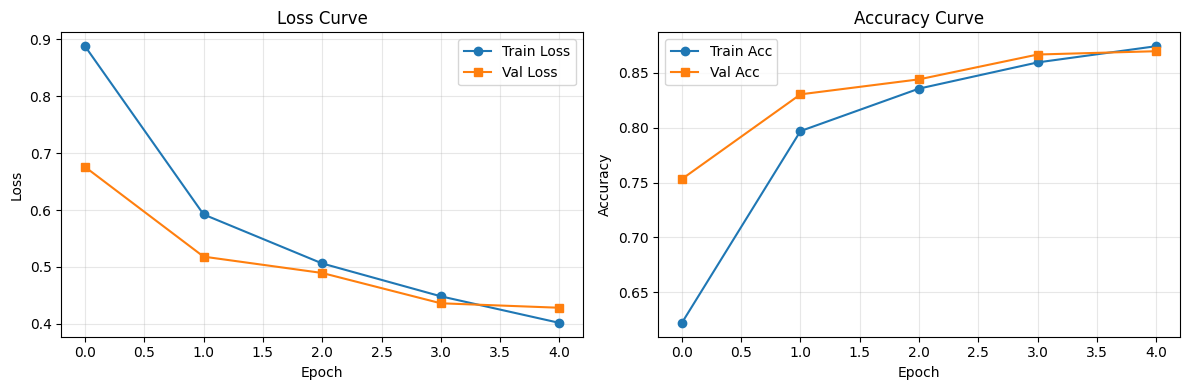

In [27]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4)
)

axes[0].plot(
    history['train_loss'],
    label='Train Loss',
    marker='o'
)

axes[0].plot(
    history['val_loss'],
    label='Val Loss',
    marker='s'
)

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history['train_acc'],
    label='Train Acc',
    marker='o'
)

axes[1].plot(
    history['val_acc'],
    label='Val Acc',
    marker='s'
)

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Accuracy Curve')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Матрица ошибок и classification report

In [28]:
val_loss, val_acc, all_preds, all_labels = evaluate(
    model,
    test_loader,
    criterion
)

print(f"Test loss: {val_loss:.4f}")
print(f"Test accuracy: {val_acc:.4f}")

Evaluating: 100%|██████████| 119/119 [00:00<00:00, 121.25it/s]

Test loss: 0.4282
Test accuracy: 0.8697


In [29]:
class_names = [
    'World',
    'Sports',
    'Business',
    'Sci/Tech'
]

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

       World       0.91      0.85      0.88      1900
      Sports       0.92      0.96      0.94      1900
    Business       0.79      0.87      0.83      1900
    Sci/Tech       0.87      0.80      0.84      1900

    accuracy                           0.87      7600
   macro avg       0.87      0.87      0.87      7600
weighted avg       0.87      0.87      0.87      7600



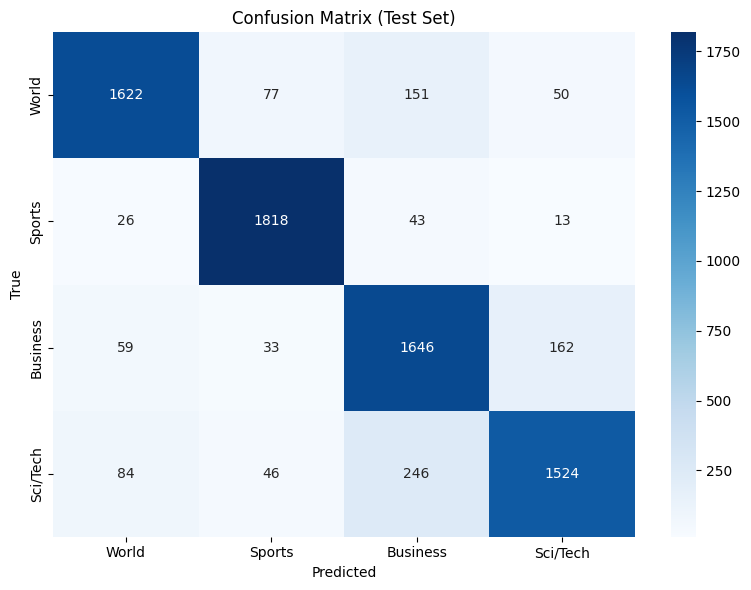

In [30]:
cm = confusion_matrix(
    all_labels,
    all_preds
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Test Set)')
plt.tight_layout()
plt.show()

## 11. Контрольные вопросы для студентов

1. **Почему в этом ноутбуке используется `pack_padded_sequence`?**  
   Что произойдёт, если убрать `pack_padded_sequence` и просто подать `padded` тензор в RNN?

2. **Как `min_freq` влияет на размер словаря и на количество параметров embedding-слоя?**  
   Оцените, как меняется число обучаемых параметров при `MIN_FREQ = 2` и `MIN_FREQ = 10`.

3. **Что означает `lengths.cpu()` в вызове `pack_padded_sequence`?**  
   Почему длины должны быть на CPU, а не на GPU?

4. **Почему при `BIDIRECTIONAL = True` используется `torch.cat([hidden[-2], hidden[-1]], dim=1)`?**  
   Что хранится в `hidden[-2]` и `hidden[-1]`?

5. **Как размер `HIDDEN_DIM` связан с числом параметров RNN?**  
   Выведите формулу для числа параметров `nn.RNN` (без bias и с bias).

6. **Почему `clip_grad_norm_` особенно важен для RNN?**  
   С каким явлением он борется?

7. **Что произойдёт, если `MAX_LEN` сделать очень большим (например, 2048)?**  
   Как это повлияет на время обучения, память и качество?

8. **Почему `padding_idx=PAD_IDX` важен в `nn.Embedding`?**  
   Что произойдёт, если его не указывать?

9. **Как интерпретировать матрицу ошибок?**  
   Какие классы чаще всего путаются и почему?

10. **Почему accuracy может быть не лучшей метрикой для этой задачи?**  
    Посмотрите на `classification_report` и объясните, какие метрики здесь информативнее.

## 12. Домашнее задание

### Часть A. Эксперименты с гиперпараметрами

Проведите **минимум 5 экспериментов**, меняя по одному гиперпараметру за раз:

1. `MIN_FREQ`: 2, 5, 10
2. `MAX_LEN`: 128, 256, 512
3. `BATCH_SIZE`: 32, 64, 128
4. `EMBED_DIM` / `HIDDEN_DIM`: (64, 64), (128, 128), (256, 256)
5. `NUM_LAYERS`: 1, 2
6. `BIDIRECTIONAL`: True / False
7. `LEARNING_RATE`: 1e-3, 5e-4, 1e-4

Для каждого эксперимента зафиксируйте:
- размер словаря;
- число параметров модели;
- время одной эпохи;
- `val_loss` и `val_acc` после 3–5 эпох.

Сведите результаты в таблицу и постройте графики зависимости `val_acc` от каждого гиперпараметра.

### Часть B. Анализ ошибок

1. Найдите **10 примеров**, на которых модель ошибается.
2. Для каждого примера укажите: истинный класс, предсказанный класс, текст (можно первые 200 символов).
3. Предложите **гипотезы**, почему модель ошибается (короткий текст, смешанная тематика, редкие слова и т.д.).
4. Предложите **2–3 идеи**, как улучшить модель именно на этих примерах.

### Часть C. Улучшение архитектуры

Замените `nn.RNN` на одну из архитектур:
- `nn.LSTM`
- `nn.GRU`
- двунаправленный LSTM/GRU

Сравните с базовой RNN по тем же метрикам. Объясните, почему LSTM/GRU часто работают лучше на длинных последовательностях.

### Часть D. Мини-исследование

Проверьте гипотезу: **«чем длиннее текст, тем лучше модель его классифицирует»**.

1. Разбейте тестовые примеры на группы по длине (например, 0–50, 51–100, 101–200, 200+ слов).
2. Посчитайте accuracy для каждой группы.
3. Постройте график зависимости accuracy от длины.
4. Сформулируйте вывод: подтверждается ли гипотеза?

### Формат сдачи

- Ноутбук `.ipynb` со всеми выполненными ячейками.
- Краткий отчёт (markdown внутри ноутбука): таблица экспериментов, графики, анализ ошибок, выводы.
- Ссылка на GitHub / Colab или сам файл.

---

## Часть A. Эксперименты с гиперпараметрами

**Идея.** В исходном ноутбуке гиперпараметры — глобальные переменные, и для каждого эксперимента пришлось бы вручную менять значение и перезапускать пол-ноутбука. Чтобы этого не делать, соберём весь пайплайн в одну функцию `run_experiment(...)`, которая принимает гиперпараметры и возвращает метрики.

**Правило честного эксперимента:** меняем **один** параметр за раз, остальные равны базовым (`BASE`). Перед каждым запуском фиксируем seed.

### A.1. Токенизируем один раз

In [31]:
import time
import pandas as pd
from functools import partial

# Токенизация 120 000 текстов — самая медленная часть предобработки.
# Делаем её один раз, а не в каждом эксперименте.
train_tokens = [tokenizer(text) for _, text in train_data]
test_tokens = [tokenizer(text) for _, text in test_data]
train_labels = [label for label, _ in train_data]
test_labels = [label for label, _ in test_data]

# Частоты слов считаем один раз; словарь для любого min_freq строится из них мгновенно
word_counter = Counter()
for tokens in train_tokens:
    word_counter.update(tokens)

print("Уникальных токенов в обучающей выборке:", len(word_counter))

Уникальных токенов в обучающей выборке: 65061


### A.2. Вспомогательные функции

In [32]:
def make_vocab(min_freq):
    """Тот же словарь, что строит build_vocab_from_iterator, но из готового счётчика."""
    words = [w for w, c in word_counter.items() if c >= min_freq]
    words.sort(key=lambda w: (-word_counter[w], w))

    vocab = {'<pad>': 0, '<unk>': 1}
    for index, word in enumerate(words, start=2):
        vocab[word] = index
    return vocab


class TokenizedDataset(torch.utils.data.Dataset):
    """Dataset поверх уже токенизированных текстов."""
    def __init__(self, token_lists, labels, vocab, max_len):
        self.token_lists = token_lists
        self.labels = labels
        self.vocab = vocab
        self.max_len = max_len

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        tokens = self.token_lists[idx][:self.max_len]          # обрезка по MAX_LEN
        ids = [self.vocab.get(t, 1) for t in tokens]           # 1 = <unk>
        if len(ids) == 0:
            ids = [1]
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )


def make_loader(token_lists, labels, vocab, max_len, batch_size, shuffle):
    dataset = TokenizedDataset(token_lists, labels, vocab, max_len)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=collate_batch,   # PAD_IDX = 0 во всех наших словарях
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

### A.3. Модель, которая умеет быть RNN, LSTM и GRU

Класс почти совпадает с `RNNClassifier`. Отличия — параметр `rnn_type` и одна строчка для LSTM: она возвращает не `h_n`, а пару `(h_n, c_n)` (скрытое состояние и состояние ячейки). Для классификации нам нужно только `h_n`.

In [33]:
class SeqClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes=4,
                 rnn_type='RNN', num_layers=1, dropout=0.2, bidirectional=False):
        super().__init__()

        rnn_class = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[rnn_type]

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        self.rnn = rnn_class(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0,
            bidirectional=bidirectional
        )

        rnn_output_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.fc = nn.Linear(rnn_output_dim, num_classes)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, lengths):
        embedded = self.dropout(self.embedding(x))

        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )

        _, hidden = self.rnn(packed)

        if isinstance(hidden, tuple):   # LSTM: (h_n, c_n) -> берём h_n
            hidden = hidden[0]

        if self.rnn.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            last_hidden = hidden[-1]

        return self.fc(self.dropout(last_hidden))

### A.4. Функция `run_experiment`

Она возвращает три вещи: строку с метриками, обученную модель и словарь.

Замеры: размер словаря, число параметров, **среднее время одной эпохи обучения** (только `train_epoch`, без оценки) и `val_loss` / `val_acc` после последней эпохи.

> **Оговорка.** Как и в исходном ноутбуке, «валидацией» служит тестовая выборка. Для учебного сравнения это допустимо, но выбирать по ней лучшую конфигурацию и одновременно отчитываться о её качестве слегка оптимистично. В реальном проекте нужно отдельно отложить часть обучающей выборки.

In [34]:
# Отключаем полосы tqdm внутри train_epoch/evaluate: иначе 13 запусков засорят вывод.
# Чтобы вернуть полосы: from tqdm import tqdm
_tqdm_original = tqdm
tqdm = partial(_tqdm_original, disable=True)


def run_experiment(min_freq=5, max_len=256, batch_size=64,
                   embed_dim=128, hidden_dim=128, num_layers=1,
                   bidirectional=False, lr=1e-3, rnn_type='RNN',
                   epochs=3, dropout=0.2):
    # одинаковый seed -> различия между запусками объясняются параметром, а не случайностью
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    vocab = make_vocab(min_freq)
    train_loader = make_loader(train_tokens, train_labels, vocab, max_len, batch_size, shuffle=True)
    test_loader = make_loader(test_tokens, test_labels, vocab, max_len, 256, shuffle=False)

    model = SeqClassifier(
        vocab_size=len(vocab), embed_dim=embed_dim, hidden_dim=hidden_dim,
        rnn_type=rnn_type, num_layers=num_layers, dropout=dropout,
        bidirectional=bidirectional
    ).to(device)

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    epoch_times = []
    for epoch in range(epochs):
        start = time.time()
        train_epoch(model, train_loader, optimizer, criterion)
        if torch.cuda.is_available():
            torch.cuda.synchronize()          # дождаться GPU, иначе время будет занижено
        epoch_times.append(time.time() - start)

    val_loss, val_acc, _, _ = evaluate(model, test_loader, criterion)

    result = {
        'vocab_size': len(vocab),
        'n_params': n_params,
        'epoch_time_s': round(float(np.mean(epoch_times)), 1),
        'val_loss': round(val_loss, 4),
        'val_acc': round(val_acc, 4),
    }
    print(f"  vocab={result['vocab_size']:,} | params={n_params:,} | "
          f"{result['epoch_time_s']} с/эпоха | val_loss={result['val_loss']} | val_acc={result['val_acc']}")
    return result, model, vocab

### A.5. Запуск экспериментов

Базовая конфигурация `BASE` совпадает с исходным ноутбуком. Базовый запуск выполняется один раз и переиспользуется во всех группах, то есть всего **13 обучений по 3 эпохи** (на GPU Colab порядка 20–30 минут).

In [35]:
BASE = dict(min_freq=5, max_len=256, batch_size=64,
            embed_dim=128, hidden_dim=128, num_layers=1,
            bidirectional=False, lr=1e-3)

# параметр -> список (подпись, что меняем относительно BASE); пустой словарь = базовое значение
grid = {
    'MIN_FREQ':        [('2', {'min_freq': 2}), ('5', {}), ('10', {'min_freq': 10})],
    'MAX_LEN':         [('128', {'max_len': 128}), ('256', {}), ('512', {'max_len': 512})],
    'BATCH_SIZE':      [('32', {'batch_size': 32}), ('64', {}), ('128', {'batch_size': 128})],
    'EMBED/HIDDEN':    [('64/64', {'embed_dim': 64, 'hidden_dim': 64}),
                        ('128/128', {}),
                        ('256/256', {'embed_dim': 256, 'hidden_dim': 256})],
    'NUM_LAYERS':      [('1', {}), ('2', {'num_layers': 2})],
    'BIDIRECTIONAL':   [('False', {}), ('True', {'bidirectional': True})],
    'LEARNING_RATE':   [('1e-3', {}), ('5e-4', {'lr': 5e-4}), ('1e-4', {'lr': 1e-4})],
}

rows = []
baseline_result = None

for param, options in grid.items():
    for label, changes in options:
        print(f"{param} = {label}")

        if changes == {}:                       # базовое значение
            if baseline_result is None:
                baseline_result, _, _ = run_experiment(**BASE, epochs=3)
            result = baseline_result
        else:
            result, _, _ = run_experiment(**{**BASE, **changes}, epochs=3)
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        rows.append({'param': param, 'setting': label, **result})

results_df = pd.DataFrame(rows)
results_df.to_csv('experiments.csv', index=False)
results_df

MIN_FREQ = 2
  vocab=44,138 | params=5,683,204 | 23.8 с/эпоха | val_loss=0.4936 | val_acc=0.8458
MIN_FREQ = 5
  vocab=27,831 | params=3,595,908 | 22.6 с/эпоха | val_loss=0.4654 | val_acc=0.852
MIN_FREQ = 10
  vocab=19,638 | params=2,547,204 | 22.5 с/эпоха | val_loss=0.479 | val_acc=0.8455
MAX_LEN = 128
  vocab=27,831 | params=3,595,908 | 21.7 с/эпоха | val_loss=0.461 | val_acc=0.8591
MAX_LEN = 256
MAX_LEN = 512
  vocab=27,831 | params=3,595,908 | 22.7 с/эпоха | val_loss=0.4836 | val_acc=0.8499
BATCH_SIZE = 32
  vocab=27,831 | params=3,595,908 | 39.4 с/эпоха | val_loss=0.4583 | val_acc=0.8529
BATCH_SIZE = 64
BATCH_SIZE = 128
  vocab=27,831 | params=3,595,908 | 13.8 с/эпоха | val_loss=0.4668 | val_acc=0.8562
EMBED/HIDDEN = 64/64
  vocab=27,831 | params=1,789,764 | 21.5 с/эпоха | val_loss=0.4789 | val_acc=0.8536
EMBED/HIDDEN = 128/128
EMBED/HIDDEN = 256/256
  vocab=27,831 | params=7,257,348 | 25.3 с/эпоха | val_loss=0.4625 | val_acc=0.8586
NUM_LAYERS = 1
NUM_LAYERS = 2
  vocab=27,831 | pa

,param,setting,vocab_size,n_params,epoch_time_s,val_loss,val_acc
0,MIN_FREQ,2,44138,5683204,23.8,0.4936,0.8458
1,MIN_FREQ,5,27831,3595908,22.6,0.4654,0.8520
2,MIN_FREQ,10,19638,2547204,22.5,0.4790,0.8455
3,MAX_LEN,128,27831,3595908,21.7,0.4610,0.8591
4,MAX_LEN,256,27831,3595908,22.6,0.4654,0.8520
5,MAX_LEN,512,27831,3595908,22.7,0.4836,0.8499
6,BATCH_SIZE,32,27831,3595908,39.4,0.4583,0.8529
7,BATCH_SIZE,64,27831,3595908,22.6,0.4654,0.8520
8,BATCH_SIZE,128,27831,3595908,13.8,0.4668,0.8562
9,EMBED/HIDDEN,64/64,27831,1789764,21.5,0.4789,0.8536


### A.6. Графики `val_acc` от каждого гиперпараметра

По одному графику на гиперпараметр (по одной ячейке).

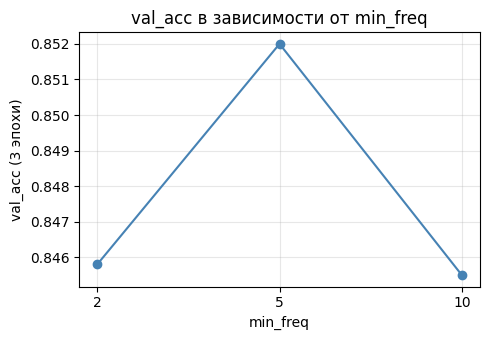

In [36]:
subset = results_df[results_df['param'] == 'MIN_FREQ']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('min_freq')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от min_freq')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

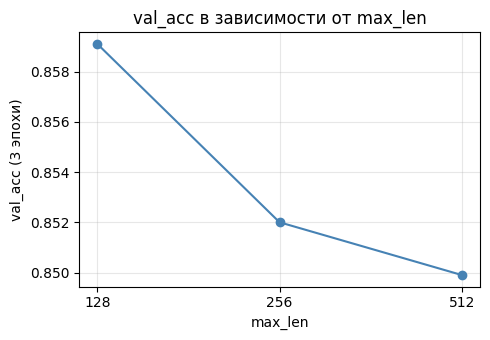

In [37]:
subset = results_df[results_df['param'] == 'MAX_LEN']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('max_len')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от max_len')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

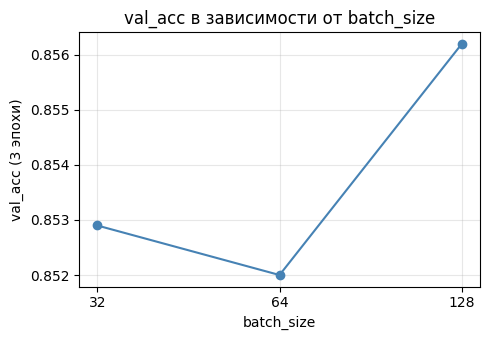

In [38]:
subset = results_df[results_df['param'] == 'BATCH_SIZE']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('batch_size')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от batch_size')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

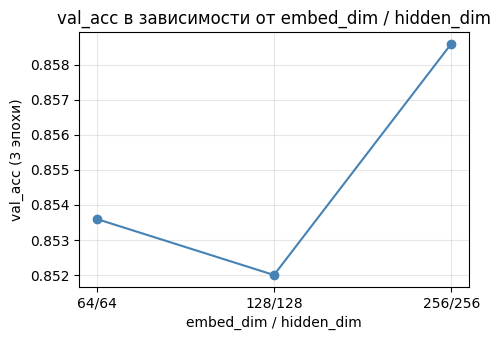

In [39]:
subset = results_df[results_df['param'] == 'EMBED/HIDDEN']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('embed_dim / hidden_dim')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от embed_dim / hidden_dim')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

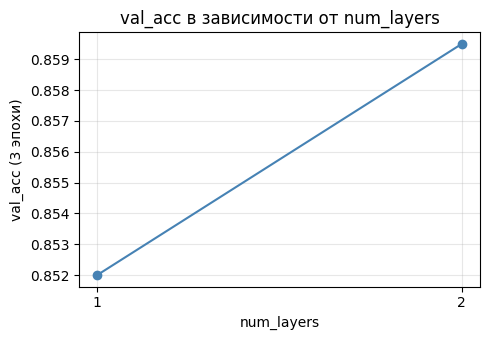

In [40]:
subset = results_df[results_df['param'] == 'NUM_LAYERS']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('num_layers')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от num_layers')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

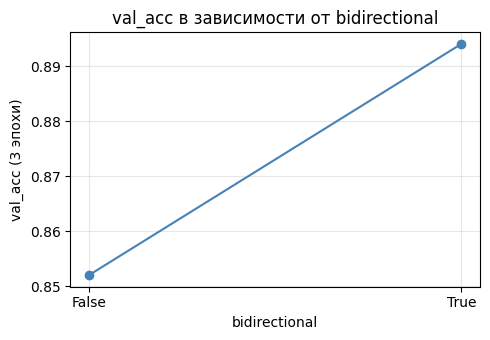

In [41]:
subset = results_df[results_df['param'] == 'BIDIRECTIONAL']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('bidirectional')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от bidirectional')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

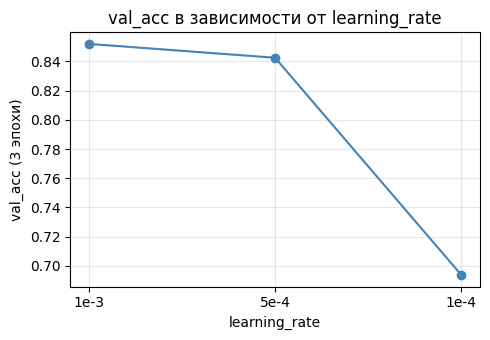

In [42]:
subset = results_df[results_df['param'] == 'LEARNING_RATE']

plt.figure(figsize=(5, 3.5))
plt.plot(subset['setting'], subset['val_acc'], marker='o', color='steelblue')
plt.xlabel('learning_rate')
plt.ylabel('val_acc (3 эпохи)')
plt.title('val_acc в зависимости от learning_rate')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы по Части A**:

**Лучшая конфигурация**:
- BIDIRECTIONAL=True (val_acc 0,8941, val_loss 0,3231). Среди остальных лучшие результаты у NUM_LAYERS=2 (0,8595), MAX_LEN=128 (0,8591) и EMBED/HIDDEN=256/256 (0,8586), но они лишь немного выше базы (0,8520) и в пределах возможного шума.
Параметр с наибольшим влиянием: двунаправленность (+4,2 п.п.) и, в обратную сторону,
- LEARNING_RATE=1e-4 (−15,8 п.п.).
Параметры, которые почти ничего не меняют: MIN_FREQ, MAX_LEN, EMBED/HIDDEN, BATCH_SIZE.

**По параметрам:**

- MIN_FREQ. Словарь сокращается, число параметров падает с 5,68 млн до 2,55 млн. Качество при этом не меняется: оба крайних значения чуть хуже базы, а время эпохи почти одинаковое, потому что эмбеддинг — просто таблица, а основное время уходит на рекуррентный проход. Вывод: на этой задаче размер словаря не критичен, min_freq=5 — разумный компромисс.
- MAX_LEN. 128, 256 и 512 дают одинаковое время эпохи. Скорее всего, большинство текстов короче 128 токенов, и обрезка почти никого не затрагивает. Тогда различия в точности — шум, а не эффект длины. Для этих данных достаточно 128.
- BATCH_SIZE. Качество одинаково, а время эпохи сильно зависит от размера батча.Время почти обратно пропорционально размеру батча, потому что меньше шагов — меньше накладных расходов на GPU. Для ускорения экспериментов удобен батч 128.
EMBED/HIDDEN. Число параметров растёт в 4 раза между (64, 64) и (128, 128) и ещё в 2 раза до (256, 256) (1,79 → 3,60 → 7,26 млн), а точность меняется в пределах шума. Модель (64, 64) с вдвое меньшим числом параметров не уступает базе. Ёмкость модели не является узким местом, ограничивает скорее сама архитектура простой RNN.
- NUM_LAYERS. Второй слой добавил всего 33 тыс. параметров и +0,75 п.п., val_loss снизился на 0,02, но время эпохи выросло на 40%. Выигрыш небольшой и на границе шума.
- BIDIRECTIONAL. Заметное улучшение: +4,2 п.п. по точности и снижение val_loss с 0,465 до 0,323 при росте параметров всего на 1% и времени эпохи на 35%. В  однонаправленной RNN для классификации берётся последнее скрытое состояние, которое «помнит» в основном конец текста, а ключевая информация (заголовок) стоит в начале. Обратный проход заканчивается как раз на начале текста.
- LEARNING_RATE. Чем меньше lr, тем хуже при фиксированных трёх эпохах: 0,852 → 0,8425 → 0,6937. При 1e-4 val_loss всё ещё 0,71, то есть модель недообучена и ей нужно больше эпох.

---
## Часть B. Анализ ошибок

Берём базовую RNN, обучаем **5 эпох** и смотрим, где она ошибается. Эта же модель понадобится в Части D.

In [43]:
base5_result, base_model, base_vocab = run_experiment(**BASE, epochs=5)

  vocab=27,831 | params=3,595,908 | 22.8 с/эпоха | val_loss=0.4261 | val_acc=0.8672


In [44]:
def get_predictions(model, vocab, max_len=256):
    loader = make_loader(test_tokens, test_labels, vocab, max_len, 256, shuffle=False)
    _, _, preds, labels = evaluate(model, loader, nn.CrossEntropyLoss())
    return np.array(preds), np.array(labels)     # порядок совпадает с test_data (shuffle=False)


base_preds, base_labels = get_predictions(base_model, base_vocab)

error_idx = np.where(base_preds != base_labels)[0]
print(f"Ошибок: {len(error_idx)} из {len(base_labels)} ({len(error_idx) / len(base_labels):.1%})")

Ошибок: 1009 из 7600 (13.3%)


### B.1. 10 случайных ошибок

Берём случайные (а не первые 10), чтобы выборка не зависела от порядка в файле.

In [45]:
sample_idx = random.Random(SEED).sample(list(error_idx), 10)

error_rows = []
for i in sample_idx:
    text = test_data[i][1]
    error_rows.append({
        'true': class_names[base_labels[i]],
        'pred': class_names[base_preds[i]],
        'n_words': len(text.split()),
        'text (первые 200 символов)': text[:200],
    })

pd.set_option('display.max_colwidth', 200)
pd.DataFrame(error_rows)

,true,pred,n_words,text (первые 200 символов)
0,Business,World,31,"Putin ready to probe other oil companies Russian President Vladimir Putin is ready to go after other oil companies the way he has hammered Yukos, a top Kremlin official has said."
1,World,Business,29,"US economic growth slips to 2.8 Annual US economic growth fell to 2.8 in the second quarter of 2004, marking a slowdown from the 3 estimated a month ago."
2,Sci/Tech,Business,48,"Hurricane center #39;s projection on Charley not far off, data show FORT LAUDERDALE, Fla. - (KRT) - Despite criticism that it should have better anticipated Hurricane Charley #39;s rapid intensifi..."
3,Sci/Tech,Business,47,"Halo 2; Donkey Konga The first Halo game sold quite a few Xboxes (we know a few Xbox owners who don't appear to play any other titles on their consoles), and Halo 2 has already clocked \$125 milli..."
4,Business,Sci/Tech,35,VoIP becomes new option Jackson is one of the first to take advantage of Time Warner Cable #39;s new venture into Voice over Internet Provider (VoIP) telephone service here and she says it works g...
5,Sports,Business,43,"GM Plans to Use Woods More Creatively (AP) AP - General Motors Corp. is thrilled that Tiger Woods will promote Buick for the next five years, but GM chairman Rick Wagoner says the automaker could ..."
6,Sci/Tech,World,36,"Training is the Key to Defibrillator Success By DANIEL YEE ALPHARETTA, Ga. (AP) -- Because defibrillators are more affordable than ever, they are quickly becoming commonplace in schools, busin..."
7,Sci/Tech,Business,20,Hall of Shame Hall of Fame We spotlight people and products that pester us...and the heroes saving us from annoyances.
8,World,Business,22,Safety Group Closely Echoes Rail Industry Documents show that the nation's most influential rail-safety group is tightly bound to the railroad industry.
9,Sci/Tech,Business,40,"U.N. Agency Sees No Rapid Development of El Nino (Reuters) Reuters - Fears of a new El Nino, a phenomenon\that brings extreme weather patterns, are unfounded despite\unusual ocean temperatures whi..."


### B.2. Проверка гипотез на всех ошибках, а не на 10 примерах

Десять примеров — слишком мало для выводов, поэтому каждую гипотезу проверяем по всем ошибкам.

In [46]:
# Гипотеза 1: путаются соседние по тематике классы (особенно Business <-> Sci/Tech)
confusions = Counter(
    (class_names[base_labels[i]], class_names[base_preds[i]]) for i in error_idx
)
print("Самые частые ошибки (истина -> предсказание):")
for (true_name, pred_name), count in confusions.most_common(5):
    print(f"  {true_name:9s} -> {pred_name:9s}: {count}")

# Гипотеза 2: ошибки чаще в коротких текстах
word_counts = np.array([len(text.split()) for _, text in test_data])
is_error = base_preds != base_labels
print(f"\nСредняя длина (слов): ошибки = {word_counts[is_error].mean():.1f}, "
      f"верные = {word_counts[~is_error].mean():.1f}")

# Гипотеза 3: в ошибочных текстах больше неизвестных (редких) слов
def unk_share(tokens):
    tokens = tokens[:256]
    return sum(1 for t in tokens if t not in base_vocab) / max(len(tokens), 1)

unk = np.array([unk_share(tokens) for tokens in test_tokens])
print(f"Доля <unk>: ошибки = {unk[is_error].mean():.3f}, верные = {unk[~is_error].mean():.3f}")

Самые частые ошибки (истина -> предсказание):
  Sci/Tech  -> Business : 299
  Business  -> Sci/Tech : 154
  Business  -> World    : 106
  World     -> Sports   : 95
  Sci/Tech  -> World    : 84

Средняя длина (слов): ошибки = 36.9, верные = 37.9
Доля <unk>: ошибки = 0.019, верные = 0.014


### B.3. Гипотезы и идеи улучшения

**Гипотезы, которые проверяет код выше**:

- Гипотеза 1 (смешанная тематика): подтверждается.

Пять самых частых пар дают 738 из 1009 ошибок (73%).
Одни только Business ↔ Sci/Tech дают 453 ошибки (299 + 154), это 45% всех ошибок.
Ошибки несимметричны: Sci/Tech принимается за Business почти вдвое чаще (299), чем наоборот (154). Модель тяготеет к Business. Вероятная причина (гипотеза): в этом классе самая «общая» лексика (company, million, sales), и такие слова перетягивают в Business даже технологические новости.
Среди 10 случайных ошибок предсказанным классом оказывается Business в 7 случаях. Выборка мала, но она согласуется с глобальной статистикой.

- Гипотеза 2 (короткий текст): не подтверждается. Средняя длина ошибочных текстов 36,9 слова, верных 37,9. Разница в одно слово маленькая. Модель ошибается не потому, что текстов мало, а потому, что они неоднозначны.

- Гипотеза 3 (редкие слова): формально да, практически нет. Доля <unk> у ошибок 1,9%, у верных 1,4%. Разница есть, но объяснить ей 13% ошибок нельзя.

- Гипотеза 4 (RNN забывает начало текста). Косвенно за неё говорит часть A: двунаправленность дала +4,2 п.п. Окончательная проверка в части C.

**Идеи улучшения:**
- Двунаправленный LSTM/GRU (часть C). Из части A: двунаправленность дала +4,2 п.п., и можно ожидать, что она помогает как раз на таких неоднозначных текстах.
Очистка текста. Заменить #39; на апостроф и убрать \ перед токенизацией. Это уберёт мусорные токены, но эффект, скорее всего, небольшой: артефакты есть и в верно классифицированных текстах.
- Предобученные эмбеддинги (GloVe, fastText). Названия компаний и продуктов получат осмысленные векторы вместо <unk>. Но по гипотезе 3 редкие слова объясняют лишь малую часть ошибок, поэтому ждать от этого большого прироста не стоит.

Также часть ошибок упирается в неоднозначность разметки, а не в слабость модели.

---
## Часть C. Улучшение архитектуры

Сравниваем RNN, LSTM, GRU и их двунаправленные варианты. Все параметры, кроме `rnn_type` и `bidirectional`, одинаковые, **5 эпох**. Результат для RNN берём из Части B (тот же запуск).

In [47]:
variants = {
    'LSTM':   dict(rnn_type='LSTM'),
    'GRU':    dict(rnn_type='GRU'),
    'BiLSTM': dict(rnn_type='LSTM', bidirectional=True),
    'BiGRU':  dict(rnn_type='GRU', bidirectional=True),
}

trained = {'RNN': (base_model, base_vocab)}        # сохраняем модели для Части D
arch_rows = [{'model': 'RNN', **base5_result}]

for name, changes in variants.items():
    print(name)
    result, model, vocab = run_experiment(**{**BASE, **changes}, epochs=5)
    trained[name] = (model, vocab)
    arch_rows.append({'model': name, **result})

arch_df = pd.DataFrame(arch_rows)
arch_df

LSTM
  vocab=27,831 | params=3,694,980 | 24.3 с/эпоха | val_loss=0.2408 | val_acc=0.9222
GRU
  vocab=27,831 | params=3,661,956 | 24.1 с/эпоха | val_loss=0.231 | val_acc=0.927
BiLSTM
  vocab=27,831 | params=3,827,588 | 34.1 с/эпоха | val_loss=0.2519 | val_acc=0.9226
BiGRU
  vocab=27,831 | params=3,761,540 | 33.3 с/эпоха | val_loss=0.2377 | val_acc=0.9255


,model,vocab_size,n_params,epoch_time_s,val_loss,val_acc
0,RNN,27831,3595908,22.8,0.4261,0.8672
1,LSTM,27831,3694980,24.3,0.2408,0.9222
2,GRU,27831,3661956,24.1,0.2310,0.9270
3,BiLSTM,27831,3827588,34.1,0.2519,0.9226
4,BiGRU,27831,3761540,33.3,0.2377,0.9255


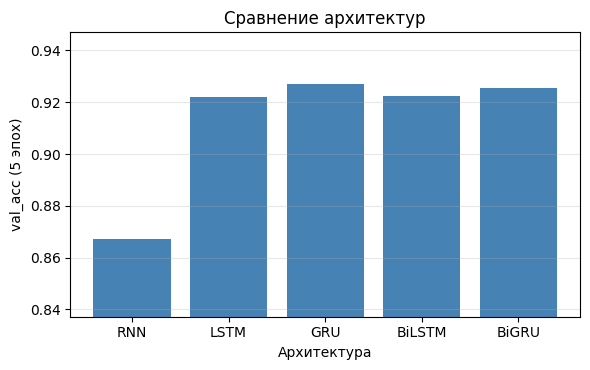

In [48]:
plt.figure(figsize=(6, 3.8))
plt.bar(arch_df['model'], arch_df['val_acc'], color='steelblue')
plt.ylim(arch_df['val_acc'].min() - 0.03, min(arch_df['val_acc'].max() + 0.02, 1.0))
plt.xlabel('Архитектура')
plt.ylabel('val_acc (5 эпох)')
plt.title('Сравнение архитектур')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Выводы части С:**
- Любая из четырёх gated-архитектур заметно лучше простой RNN: accuracy выросла с 0,867 до 0,922–0,927, val_loss почти вдвое меньше. Доля ошибок снизилась с 13,3% до 7,3% у лучшей модели (GRU) примерно на 45%.

- Различия между LSTM, GRU, BiLSTM и BiGRU лежат в пределах шума. Все четыре укладываются в диапазон 0,9222–0,9270, а каждая конфигурация обучалась с одним seed. Номинально лучшая — GRU, и она же самая экономная среди gated-моделей (на треть меньше добавочных параметров, чем у LSTM).

- Двунаправленность для gated-моделей ничего не дала. BiLSTM +0,04 п.п. к LSTM, BiGRU −0,15 п.п. к GRU, то есть в пределах шума, а время эпохи при этом выросло на 40%. Для простой RNN в части A двунаправленность дала +4,2 п.п. Это согласуется с гипотезой: в однонаправленной RNN последнее состояние «помнит» в основном конец текста, а двунаправленность подводит к итоговому состоянию ещё и начало. LSTM и GRU удерживают начало текста сами, поэтому второй проход становится лишним.

Практический вывод: для этой задачи оптимальный выбор — однонаправленная GRU: лучшее или сопоставимое качество при минимальных затратах.

---
## Часть D. Мини-исследование: «чем длиннее текст, тем лучше модель его классифицирует»

**План:** разбить тест по длине (в словах), посчитать accuracy в каждой группе, построить график.

**Про выбор групп.** Задание предлагает границы 0–50, 51–100, 101–200, 200+. Но тексты AG News в основном короткие, и в группах «101–200» и «200+» могут оказаться единицы-десятки примеров, а accuracy по 5 примерам ничего не значит. Поэтому используем более мелкие границы в области, где лежит основная масса данных, и **обязательно показываем размер каждой группы** (`n`).

Проверим гипотезу на двух моделях: базовой RNN и лучшей из Части C. Если выводы совпадут, они устойчивее.

In [49]:
lengths = np.array([len(text.split()) for _, text in test_data])

bins = [-1, 30, 40, 50, 60, 80, np.inf]
group_names = ['≤30', '31–40', '41–50', '51–60', '61–80', '80+']
groups = pd.cut(lengths, bins=bins, labels=group_names)

best_name = arch_df.sort_values('val_acc').iloc[-1]['model']
print("Лучшая модель из Части C:", best_name)

def accuracy_by_length(model_name):
    model, vocab = trained[model_name]
    preds, labels = get_predictions(model, vocab)
    correct = pd.Series(preds == labels)
    table = correct.groupby(groups, observed=False).agg(['mean', 'count'])
    table.columns = ['accuracy', 'n']
    return table

rnn_by_len = accuracy_by_length('RNN')
best_by_len = accuracy_by_length(best_name)

length_table = pd.DataFrame({
    'n': rnn_by_len['n'],
    'acc_RNN': rnn_by_len['accuracy'].round(4),
    f'acc_{best_name}': best_by_len['accuracy'].round(4),
})
length_table

Лучшая модель из Части C: GRU


,n,acc_RNN,acc_GRU
≤30,1566,0.8129,0.8876
31–40,3413,0.8851,0.9350
41–50,2130,0.8883,0.9474
51–60,320,0.8656,0.9312
61–80,136,0.7206,0.8603
80+,35,0.8571,0.8857


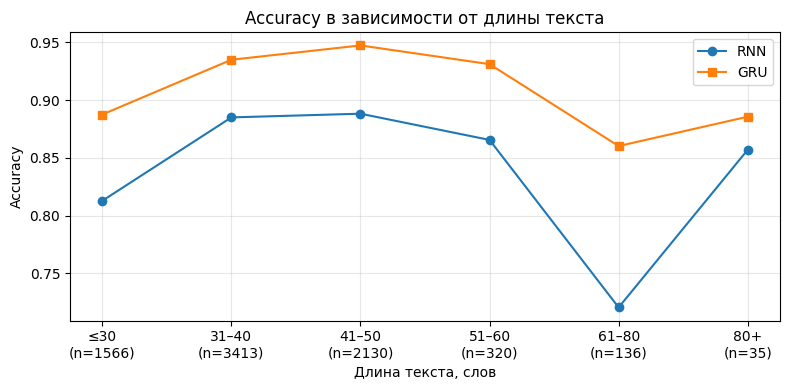

In [50]:
x_labels = [f"{name}\n(n={n})" for name, n in zip(length_table.index, length_table['n'])]

plt.figure(figsize=(8, 4))
plt.plot(x_labels, length_table['acc_RNN'], marker='o', label='RNN')
plt.plot(x_labels, length_table[f'acc_{best_name}'], marker='s', label=best_name)
plt.xlabel('Длина текста, слов')
plt.ylabel('Accuracy')
plt.title('Accuracy в зависимости от длины текста')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- Гипотеза «чем длиннее текст, тем лучше модель его классифицирует» не подтверждается или подтвержается частично. Точность растёт от самых коротких текстов к середине, достигает максимума в группе 41–50 слов (GRU 0,947, RNN 0,888), а дальше снижается. Одинаково ведут себя обе модели.

- Рост на коротких текстах реален. Переход от ≤30 к 41–50 слов даёт +6,0 п.п. у GRU и +7,5 п.п. у RNN. Группы большие (1566 и 2130 примеров), интервалы не пересекаются, и такой разрыв нельзя списать на шум.
- Падение на длинных текстах лишь частично надёжно. Для 61–80 слов (n = 136) accuracy GRU 0,860, на 8,7 п.п. ниже максимума, что превышает погрешность примерно втрое. У RNN падение ещё глубже (0,721, то есть −17 п.п.). Для 51–60 слов разница с максимумом (−1,6 п.п. у GRU) в пределах шума. Группа 80+ (n = 35, всего 35 примеров) не информативна: интервал ±10 п.п. перекрывает любые выводы, и её более высокая accuracy у RNN (0,857 против 0,721 в соседней группе) это шум.
- Разрыв между моделями растёт на длинных текстах. GRU лучше RNN на 5–7 п.п. на 30–60 словах и на 14 п.п. на 61–80.

In [51]:
class_share = pd.crosstab(groups, np.array(test_labels), normalize='index')
class_share.columns = class_names
class_share.round(3)

,World,Sports,Business,Sci/Tech
row_0,,,,
≤30,0.236,0.240,0.203,0.321
31–40,0.218,0.268,0.275,0.239
41–50,0.301,0.233,0.267,0.199
51–60,0.284,0.200,0.197,0.319
61–80,0.346,0.360,0.074,0.221
80+,0.171,0.029,0.086,0.714


---
## Общий итог

- Базовая RNN после 5 эпох достигла accuracy 0,867 на AG News.
- В части A заметное влияние показали только два параметра: двунаправленность (+4,2 п.п. за 3 эпохи) и слишком малый learning_rate = 1e-4.
Параметры min_freq, max_len, embed/hidden и batch_size (по качеству) дали различия в пределах шума, зато размер батча сильно влияет на время эпохи (39,6 с при 32 и 13,9 с при 128).
- В части B на пары Business ↔ Sci/Tech приходится 45% ошибок (453 из 1009): ошибки связаны в первую очередь с размытыми границами классов, а не с редкими словами. Замена RNN на LSTM или GRU (часть C) подняла accuracy до 0,922–0,927 (+5,5…+6,0 п.п.) при росте времени эпохи всего на 6–7%; различия между LSTM, GRU и их двунаправленными вариантами укладываются в шум, а двунаправленность для них ничего не дала.
- В части D гипотеза «чем длиннее текст, тем лучше» подтвердилась частично: точность максимальна на текстах в 41–50 слов и снижается как на коротких, так и на длинных, причём у RNN сильнее. Ограничения: один seed на конфигурацию, тестовая выборка в роли валидации, малые группы длинных текстов в части D и не исключённое влияние состава классов на её результат.